## 1. Setup and paths

Configure paths for Kaggle (competition) vs local. No full EDA here—only what we need for **validation design**.

In [35]:
!pip install monai -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 27.8 MB/s eta 0:00:00a 0:00:01


In [16]:
!ls /kaggle/input/datasets/vladimirsydor

lidc-classification-ct-scans


In [43]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
from typing import Iterable, Optional, Tuple, Union, Sequence, List

import nibabel as nib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pytorch_lightning as pl
import torchmetrics
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

from monai.data import CacheNTransDataset

from monai.transforms import (
    MapTransform,
)
from monai.config import KeysCollection
from monai.utils import ensure_tuple_rep

In [44]:
# Data root: Kaggle input vs local
if Path("/kaggle/input").exists():
    DATA_DIR = Path("/kaggle/input/competitions/lidc-lung-nodule-classification")
else:
    DATA_DIR = Path()  # or set to your local path

train_path = DATA_DIR / "train.parquet"
test_path = DATA_DIR / "test.csv"
assert train_path.exists(), f"Train not found: {train_path}"
print("Train path:", train_path)
print("Test path:", test_path, "exists:", test_path.exists())

Train path: /kaggle/input/competitions/lidc-lung-nodule-classification/train.parquet
Test path: /kaggle/input/competitions/lidc-lung-nodule-classification/test.csv exists: True


### CT scans (volumes)

In [45]:
# Where are the CT scans? (Kaggle often uses a subfolder like "scans" or "nifti")
# List competition dir to find the scan folder if needed
if DATA_DIR.exists():
    subdirs = [d.name for d in DATA_DIR.iterdir() if d.is_dir()]
    print("Data dir contents:", list(DATA_DIR.iterdir())[:15], "\nSubdirs:", subdirs)

# Convention: one NIfTI per scan, path = SCANS_DIR / f"{image_id}.nii.gz"
SCANS_DIR = DATA_DIR / "scans"   # or DATA_DIR / "nifti" — adjust to actual competition layout
if not SCANS_DIR.exists():
    SCANS_DIR = Path("/kaggle/input/datasets/vladimirsydor/lidc-classification-ct-scans")
print("\nSCANS_DIR:", SCANS_DIR)

Data dir contents: [PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/sample_submission.csv'), PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/train.parquet'), PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/test.csv')] 
Subdirs: []

SCANS_DIR: /kaggle/input/datasets/vladimirsydor/lidc-classification-ct-scans


![my brain](https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_3/images/LIDC_example.png)

In [46]:
# Build image path for each row: image_id -> path to 3D volume
def image_id_to_path(image_id, scans_dir=SCANS_DIR, suffix=".nii"):
    return Path(scans_dir) / f"{image_id}{suffix}"

# Your scans use .nii (use suffix=".nii.gz" if needed)
train_df = pd.read_parquet(train_path)  # reload so we have train_df before later cells
train_df["image_path"] = train_df["image_id"].apply(lambda x: image_id_to_path(x))

# Existence check
existing = train_df["image_path"].apply(lambda p: Path(p).exists())
print("Train: rows with existing scan file:", existing.sum(), "/", len(train_df))
if not existing.all():
    missing = train_df.loc[~existing, "image_id"].unique()
    print("Missing image_ids (first 10):", list(missing)[:10])

Train: rows with existing scan file: 1986 / 1986


In [19]:
# Sanity check: load one CT volume and verify shape vs bbox
try:
    import nibabel as nib
    row = train_df.iloc[0]
    path = Path(row["image_path"])
    if path.exists():
        img = nib.load(str(path))
        vol = img.get_fdata()
        shape = vol.shape
        bbox = np.array(row["bbox"], dtype=int)  # [x0, y0, z0, x1, y1, z1]
        in_bounds = (bbox[0] >= 0 and bbox[3] <= shape[0] and
                     bbox[1] >= 0 and bbox[4] <= shape[1] and
                     bbox[2] >= 0 and bbox[5] <= shape[2])
        print("Sample volume shape (x,y,z):", shape)
        print("Sample bbox [x0,y0,z0,x1,y1,z1]:", bbox.tolist())
        print("Bbox within volume:", in_bounds)
        print("Dtype, value range:", vol.dtype, float(vol.min()), "-", float(vol.max()))
    else:
        print("Sample path not found; run on Kaggle or set SCANS_DIR to your NIfTI folder.")
except Exception as e:
    print("Nibabel check failed (install nibabel if needed):", e)

Sample volume shape (x,y,z): (512, 512, 465)
Sample bbox [x0,y0,z0,x1,y1,z1]: [423, 258, 190, 425, 264, 193]
Bbox within volume: True
Dtype, value range: float64 -3024.0 - 1798.0


## 2. Data analysis for validation design

We need to answer:
- **Grouping**: Are there multiple nodules per patient or per scan? (If yes, we must split by group to avoid leakage.)
- **Labels**: How are classes distributed? (Drives stratified splits.)
- **Train vs test**: Same patients/scans in both? (Affects how well CV approximates LB.)

In [20]:
# train_df already loaded above (with image_path); load test metadata
test_df = pd.read_csv(test_path) if test_path.exists() else None

print("Train shape:", train_df.shape)
print("Train columns:", list(train_df.columns))
print()
if test_df is not None:
    print("Test shape:", test_df.shape)
    print("Test columns:", list(test_df.columns))

Train shape: (1986, 11)
Train columns: ['id', 'image_id', 'object_id', 'patient_id', 'series_name', 'study_id', 'segmentMap', 'bbox', 'label', 'label_id', 'image_path']

Test shape: (280, 7)
Test columns: ['id', 'image_id', 'object_id', 'patient_id', 'series_name', 'study_id', 'bbox']


In [21]:
# Grouping structure: one row = one nodule; multiple nodules per scan/patient
patients = train_df["patient_id"].nunique()
scans = train_df["image_id"].nunique()
nodules = len(train_df)

print("Unique patients:", patients)
print("Unique scans (image_id):", scans)
print("Total nodules (rows):", nodules)
print()
print("Nodules per patient (min, median, max):", 
      train_df.groupby("patient_id").size().agg(["min", "median", "max"]).tolist())
print("Nodules per scan (min, median, max):",
      train_df.groupby("image_id").size().agg(["min", "median", "max"]).tolist())

Unique patients: 680
Unique scans (image_id): 680
Total nodules (rows): 1986

Nodules per patient (min, median, max): [1.0, 2.0, 21.0]
Nodules per scan (min, median, max): [1.0, 2.0, 21.0]


In [22]:
# Label distribution (incl. Indeterminate) — needed for stratified splits
print("Label distribution (train):")
print(train_df["label"].value_counts().sort_index())
print()
print("label_id distribution:")
print(train_df["label_id"].value_counts().sort_index())
# For validation we typically exclude Indeterminate (label_id == -1) or treat separately
train_with_label = train_df[train_df["label_id"] >= 0]
print("\nRows with valid label (label_id >= 0):", len(train_with_label))
print("Class counts (valid only):", train_with_label["label_id"].value_counts().sort_index().to_dict())

Label distribution (train):
label
Highly Suspicious        131
Highly Unlikely          250
Indeterminate            918
Moderately Suspicious    269
Moderately Unlikely      418
Name: count, dtype: int64

label_id distribution:
label_id
-1    918
 0    250
 1    418
 2    269
 3    131
Name: count, dtype: int64

Rows with valid label (label_id >= 0): 1068
Class counts (valid only): {0: 250, 1: 418, 2: 269, 3: 131}


In [23]:
# Train vs test overlap: do we share patients or scans? (affects CV–LB correlation)
if test_df is not None and "patient_id" in test_df.columns:
    train_patients = set(train_df["patient_id"].unique())
    test_patients = set(test_df["patient_id"].unique())
    overlap_patients = train_patients & test_patients
    print("Patients in train:", len(train_patients))
    print("Patients in test:", len(test_patients))
    print("Overlap (same patient in both):", len(overlap_patients))
if test_df is not None and "image_id" in test_df.columns:
    train_scans = set(train_df["image_id"].unique())
    test_scans = set(test_df["image_id"].unique())
    overlap_scans = train_scans & test_scans
    print("\nScans in train:", len(train_scans))
    print("Scans in test:", len(test_scans))
    print("Overlap (same scan in both):", len(overlap_scans))
if test_df is None:
    print("Test file not found; run on Kaggle to check train/test overlap.")

Patients in train: 680
Patients in test: 143
Overlap (same patient in both): 0

Scans in train: 680
Scans in test: 143
Overlap (same scan in both): 0


In [24]:
# Stratification feasibility: can we stratify by label within each group?
# If some patients have only one class, StratifiedGroupKFold may drop or warn
per_patient_labels = train_with_label.groupby("patient_id")["label_id"].nunique()
patients_single_class = (per_patient_labels == 1).sum()
patients_multi_class = (per_patient_labels > 1).sum()
print("Patients with only one class (nodules):", patients_single_class)
print("Patients with multiple classes:", patients_multi_class)
print("Feasible for StratifiedGroupKFold by patient_id:", "yes (stratify by label, group by patient)")

Patients with only one class (nodules): 339
Patients with multiple classes: 180
Feasible for StratifiedGroupKFold by patient_id: yes (stratify by label, group by patient)


### Sample CT visualization

Inspect a few axial slices of a cropped nodule volume and animate the full crop as a GIF.

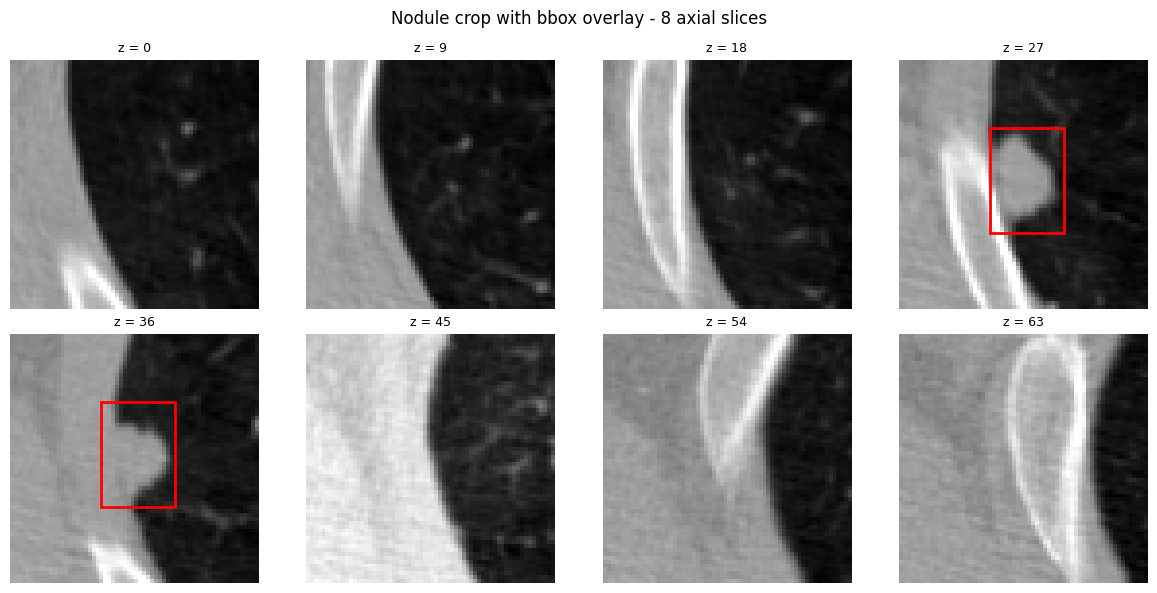

In [48]:
def show_nodule_slices(image_path, bbox, crop_size=(64, 64, 64), n_slices=8, n_cols=4):
    """Display n_slices evenly-spaced axial slices from the nodule crop."""
    img = nib.load(str(image_path))
    vol = img.get_fdata().astype(np.float32)

    x0, y0, z0, x1, y1, z1 = [int(v) for v in bbox]
    x0, x1 = sorted((x0, x1))
    y0, y1 = sorted((y0, y1))
    z0, z1 = sorted((z0, z1))

    cx, cy, cz = (x0 + x1) // 2, (y0 + y1) // 2, (z0 + z1) // 2
    hx, hy, hz = crop_size[0] // 2, crop_size[1] // 2, crop_size[2] // 2

    xs = slice(max(cx - hx, 0), min(cx + hx, vol.shape[0]))
    ys = slice(max(cy - hy, 0), min(cy + hy, vol.shape[1]))
    zs = slice(max(cz - hz, 0), min(cz + hz, vol.shape[2]))
    crop = vol[xs, ys, zs]

    bx0 = int(np.clip(x0 - xs.start, 0, crop.shape[0] - 1))
    bx1 = int(np.clip(x1 - xs.start, 0, crop.shape[0] - 1))
    by0 = int(np.clip(y0 - ys.start, 0, crop.shape[1] - 1))
    by1 = int(np.clip(y1 - ys.start, 0, crop.shape[1] - 1))
    bz0 = int(np.clip(z0 - zs.start, 0, crop.shape[2] - 1))
    bz1 = int(np.clip(z1 - zs.start, 0, crop.shape[2] - 1))

    # Clip to soft-tissue CT window, then normalize to [0, 1]
    crop = np.clip(crop, -1024, 700)
    crop = (crop - crop.min()) / (crop.max() - crop.min() + 1e-8)

    n_rows = (n_slices + n_cols - 1) // n_cols
    z_indices = np.linspace(0, crop.shape[2] - 1, n_slices, dtype=int)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.atleast_1d(axes).flatten()

    for i, z_idx in enumerate(z_indices):
        axes[i].imshow(crop[:, :, z_idx].T, cmap="gray", origin="lower")
        axes[i].set_title(f"z = {z_idx}", fontsize=9)

        if bz0 <= z_idx <= bz1:
            rect = Rectangle(
                (bx0, by0),
                bx1 - bx0 + 1,
                by1 - by0 + 1,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
            axes[i].add_patch(rect)

        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    fig.suptitle(f"Nodule crop with bbox overlay - {n_slices} axial slices", fontsize=12)
    plt.tight_layout()
    plt.show()


try:
    row = train_df.iloc[2]
    path = Path(row["image_path"])
    if path.exists():
        show_nodule_slices(path, row["bbox"])
    else:
        print("Scan not found locally. Run on Kaggle to see the visualization.")
except Exception as e:
    print("Visualization failed:", e)

In [39]:
def show_bbox_crop_gif(
    image_path: Union[str, Path],
    bbox_xyzxyz: Union[np.ndarray, Iterable[int]],
    name: str = "nodule",
    crop_size: Tuple[int, int, int] = (64, 64, 64),  # (sx, sy, sz) in voxels
    axis: int = 2,                                   # 0=x, 1=y, 2=z
    fps: int = 8,
    rotate_k: int = 0,                               # np.rot90 per frame (0..3)
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    figsize: Tuple[float, float] = (5.5, 5.5),
    bbox_linewidth: float = 2.0,
) -> HTML:
    """
    Load NIfTI, take fixed-size crop around bbox center, animate slices,
    and overlay bbox only on slices that intersect the nodule.
    """
    image_path = Path(image_path)
    bbox = np.asarray(list(bbox_xyzxyz), dtype=int)
    if bbox.shape != (6,):
        raise ValueError(f"bbox_xyzxyz must be 6 ints [x0,y0,z0,x1,y1,z1], got {bbox.shape}")

    # 1) Load
    img = nib.load(str(image_path))
    vol = np.asanyarray(img.dataobj)
    if vol.ndim > 3:
        vol = vol[..., 0]
    sx, sy, sz = vol.shape[:3]

    # normalize + clip bbox to volume
    x0, y0, z0, x1, y1, z1 = bbox.tolist()
    x0, x1 = sorted((x0, x1))
    y0, y1 = sorted((y0, y1))
    z0, z1 = sorted((z0, z1))

    x0 = int(np.clip(x0, 0, sx - 1)); x1 = int(np.clip(x1, 0, sx - 1))
    y0 = int(np.clip(y0, 0, sy - 1)); y1 = int(np.clip(y1, 0, sy - 1))
    z0 = int(np.clip(z0, 0, sz - 1)); z1 = int(np.clip(z1, 0, sz - 1))

    # center
    cx = (x0 + x1) / 2.0
    cy = (y0 + y1) / 2.0
    cz = (z0 + z1) / 2.0

    # 2) fixed-size crop around center (pad if needed)
    csx, csy, csz = map(int, crop_size)
    hx, hy, hz = csx // 2, csy // 2, csz // 2

    xs0 = int(np.round(cx)) - hx
    ys0 = int(np.round(cy)) - hy
    zs0 = int(np.round(cz)) - hz
    xs1 = xs0 + csx
    ys1 = ys0 + csy
    zs1 = zs0 + csz

    xs_i, xs_e = max(xs0, 0), min(xs1, sx)
    ys_i, ys_e = max(ys0, 0), min(ys1, sy)
    zs_i, zs_e = max(zs0, 0), min(zs1, sz)

    crop = vol[xs_i:xs_e, ys_i:ys_e, zs_i:zs_e].astype(np.float32)

    pad_before_x = xs_i - xs0
    pad_before_y = ys_i - ys0
    pad_before_z = zs_i - zs0
    pad_after_x = xs1 - xs_e
    pad_after_y = ys1 - ys_e
    pad_after_z = zs1 - zs_e

    pad_width = (
        (pad_before_x, pad_after_x),
        (pad_before_y, pad_after_y),
        (pad_before_z, pad_after_z),
    )
    if any(p > 0 for pair in pad_width for p in pair):
        fill = float(np.min(crop)) if crop.size else 0.0
        crop = np.pad(crop, pad_width, mode="constant", constant_values=fill)

    if crop.shape != (csx, csy, csz):
        raise RuntimeError(f"Crop shape {crop.shape} != requested {crop_size}")

    # bbox coords in crop space (shift by crop origin in source volume: xs0,ys0,zs0)
    bx0 = int(np.clip(x0 - xs0, 0, csx - 1)); bx1 = int(np.clip(x1 - xs0, 0, csx - 1))
    by0 = int(np.clip(y0 - ys0, 0, csy - 1)); by1 = int(np.clip(y1 - ys0, 0, csy - 1))
    bz0 = int(np.clip(z0 - zs0, 0, csz - 1)); bz1 = int(np.clip(z1 - zs0, 0, csz - 1))

    # intensity window
    if vmin is None or vmax is None:
        lo, hi = np.percentile(crop, [1, 99])
        vmin = lo if vmin is None else vmin
        vmax = hi if vmax is None else vmax

    if axis not in (0, 1, 2):
        raise ValueError("axis must be 0 (x), 1 (y), or 2 (z)")

    n_frames = crop.shape[axis]
    if n_frames < 2:
        raise ValueError(f"Not enough frames along axis={axis} (n_frames={n_frames}).")

    # --- helpers for rectangle rotation ---
    def rot_rect(rect, orig_shape, k):
        """Rotate rect (x,y,w,h) defined in (col,row) coords along with rot90 k times CCW."""
        x, y, w, h = rect
        corners = np.array(
            [[x, y], [x + w - 1, y], [x, y + h - 1], [x + w - 1, y + h - 1]],
            dtype=float,
        )
        H0, W0 = orig_shape  # rows, cols
        k = k % 4
        if k == 0:
            new = corners
        elif k == 1:
            new = np.stack([corners[:, 1], (W0 - 1) - corners[:, 0]], axis=1)
        elif k == 2:
            new = np.stack([(W0 - 1) - corners[:, 0], (H0 - 1) - corners[:, 1]], axis=1)
        else:
            new = np.stack([(H0 - 1) - corners[:, 1], corners[:, 0]], axis=1)

        x_min, y_min = new.min(axis=0)
        x_max, y_max = new.max(axis=0)
        return (float(x_min), float(y_min), float(x_max - x_min + 1), float(y_max - y_min + 1))

    # slice extraction + rect (only if intersects bbox along axis)
    def frame_and_rect(i: int):
        # determine if current slice intersects bbox along chosen axis
        if axis == 2:
            intersects = (bz0 <= i <= bz1)
            frame0 = crop[:, :, i]
            rect0 = (by0, bx0, (by1 - by0 + 1), (bx1 - bx0 + 1))  # (col=y, row=x)
        elif axis == 1:
            intersects = (by0 <= i <= by1)
            frame0 = crop[:, i, :]
            rect0 = (bz0, bx0, (bz1 - bz0 + 1), (bx1 - bx0 + 1))  # (col=z, row=x)
        else:
            intersects = (bx0 <= i <= bx1)
            frame0 = crop[i, :, :]
            rect0 = (bz0, by0, (bz1 - bz0 + 1), (by1 - by0 + 1))  # (col=z, row=y)

        frame0 = np.asarray(frame0, dtype=np.float32)
        frame = np.rot90(frame0, k=rotate_k % 4) if (rotate_k % 4) else frame0

        if not intersects:
            return frame, None  # <-- this makes bbox disappear

        rect = rot_rect(rect0, frame0.shape, rotate_k)
        return frame, rect

    # --- plot ---
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    ax.set_title(f"{name} | crop={crop_size} | axis={axis} | {image_path.name[:10]}...", fontsize=10)

    frame0, rect0 = frame_and_rect(0)
    im = ax.imshow(frame0, cmap="gray", vmin=vmin, vmax=vmax)

    rect_patch = Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", linewidth=bbox_linewidth)
    ax.add_patch(rect_patch)

    txt = ax.text(
        0.02, 0.98, "", color="white", transform=ax.transAxes,
        va="top", ha="left", fontsize=10
    )

    interval_ms = int(1000 / max(1, fps))

    def update(i: int):
        frame, rect = frame_and_rect(i)
        im.set_data(frame)

        if rect is None:
            rect_patch.set_visible(False)
        else:
            rect_patch.set_visible(True)
            rect_patch.set_xy((rect[0], rect[1]))
            rect_patch.set_width(rect[2])
            rect_patch.set_height(rect[3])

        txt.set_text(f"slice {i+1}/{n_frames}")
        return im, rect_patch, txt

    anim = FuncAnimation(fig, update, frames=n_frames, interval=interval_ms, blit=False)
    plt.close(fig)

    return HTML(anim.to_jshtml())

In [41]:
sample_id = 1

show_bbox_crop_gif(
    image_path=train_df.iloc[sample_id]["image_path"],
    bbox_xyzxyz=train_df.iloc[sample_id]["bbox"],
    name="Example nodule",
    crop_size=(64, 64, 64),
    axis=1,
    fps=8,
    rotate_k=0,
)

## 3. Validation strategy 


- **Group by `patient_id`** so the same patient never appears in both train and val (avoids leakage; multiple nodules per patient).
- **Stratify by `label_id`** (on rows with `label_id >= 0`) so each fold keeps similar class distribution.
- Use **fixed seed** and **same splits for all experiments** so CV is comparable across models.

In [25]:
# StratifiedGroupKFold: same splits for all experiments
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS = 5
RANDOM_STATE = 42

# Only rows with valid labels (exclude Indeterminate)
train_valid = train_df[train_df["label_id"] >= 0].copy()
train_df["fold"] = -1  # -1 = Indeterminate (unused in CV)

sgk = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
for fold_num, (train_idx, val_idx) in enumerate(sgk.split(
    train_valid, train_valid["label_id"], train_valid["patient_id"]
)):
    # val_idx are indices into train_valid; map back to train_df
    train_df.loc[train_valid.index[val_idx], "fold"] = fold_num

# Summary
print("Fold assignment (valid rows only):")
print(train_df[train_df["fold"] >= 0]["fold"].value_counts().sort_index())
print("\nTrain/val sizes per fold (example fold 0):")
f0_val = train_df["fold"] == 0
f0_train = (train_df["fold"] >= 0) & (train_df["fold"] != 0)
print("  Train:", f0_train.sum(), "  Val:", f0_val.sum())

Fold assignment (valid rows only):
fold
0    215
1    220
2    216
3    199
4    218
Name: count, dtype: int64

Train/val sizes per fold (example fold 0):
  Train: 853   Val: 215


**Using folds in training:** For fold `f`, train on `train_df[(train_df["fold"] >= 0) & (train_df["fold"] != f)]`, validate on `train_df[train_df["fold"] == f]`. Use the same `N_SPLITS` and `RANDOM_STATE` everywhere so all models share the same splits.

## 4. Data pipeline and training (2D / 2.5D / 3D)

In [42]:
# Imports for training: add Lecture_3 so we can import lecture_utils
import sys
from pathlib import Path
_module2 = Path(".").resolve()
_lecture3 = _module2 / "Lecture_3"
if _lecture3.exists() and str(_lecture3) not in sys.path:
    sys.path.insert(0, str(_lecture3))

import torch
import torch.nn as nn
import monai
import timm
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, LearningRateMonitor
from pytorch_lightning.loggers import WandbLogger
from sklearn.utils.class_weight import compute_class_weight

from lecture_utils import CenterCropAroundBBoxd, LitImageDataModule, LitCNNModule

# Optional: set W&B key (e.g. from env or paste; on Kaggle use Secrets)
# os.environ["WANDB_API_KEY"] = "your_key"
import wandb

ModuleNotFoundError: No module named 'lecture_utils'

In [ ]:
# Shared MONAI transforms: load NIfTI, crop around bbox, CT window, augmentations (train only)
CROP_SIZE = (64, 64, 64)

train_transforms = monai.transforms.Compose([
    monai.transforms.LoadImaged(keys=["image"], dtype="float32"),
    monai.transforms.EnsureChannelFirstd(keys=["image"]),
    CenterCropAroundBBoxd(
        keys=["image"], bbox_key="bbox", crop_size=CROP_SIZE,
        pad_mode="constant", pad_value=-1024.0,
    ),
    monai.transforms.ScaleIntensityRanged(
        keys=["image"], a_min=-1024, a_max=700.0, b_min=0.0, b_max=1.0, clip=True,
    ),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=0),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=1),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=2),
    monai.transforms.RandRotate90d(keys=["image"], prob=0.4, max_k=3, spatial_axes=(0, 1)),
    monai.transforms.RandZoomd(keys=["image"], prob=0.2, min_zoom=0.9, max_zoom=1.1, mode="trilinear", align_corners=False),
    monai.transforms.RandGaussianNoised(keys=["image"], prob=0.15, mean=0.0, std=0.02),
    monai.transforms.RandGaussianSmoothd(keys=["image"], prob=0.15, sigma_x=(0.5, 1.0), sigma_y=(0.5, 1.0), sigma_z=(0.5, 1.0)),
])

val_transforms = monai.transforms.Compose([
    monai.transforms.LoadImaged(keys=["image"], dtype="float32"),
    monai.transforms.EnsureChannelFirstd(keys=["image"]),
    CenterCropAroundBBoxd(
        keys=["image"], bbox_key="bbox", crop_size=CROP_SIZE,
        pad_mode="constant", pad_value=-1024.0,
    ),
    monai.transforms.ScaleIntensityRanged(
        keys=["image"], a_min=-1024, a_max=700.0, b_min=0.0, b_max=1.0, clip=True,
    ),
])
print("Train/val transforms defined.")

In [ ]:
# Class weights for imbalanced classes (optional)
df_cv = train_df[train_df["fold"] >= 0]
labels_np = df_cv["label_id"].values
classes = np.unique(labels_np)
weights = compute_class_weight("balanced", classes=classes, y=labels_np)
class_weights = torch.tensor(weights, dtype=torch.float32)
print("Class weights:", class_weights.tolist())

In [ ]:
# 2D classifier: 3D volume -> center slice -> 2D CNN (EfficientNet)
class Timm2DClassifier(nn.Module):
    def __init__(self, timm_config):
        super().__init__()
        self.cnn2d = timm.create_model(**timm_config)

    def forward(self, volume):
        z_mid = volume.shape[-1] // 2
        slice_2d = volume[..., z_mid]
        return self.cnn2d(slice_2d)

In [ ]:
# Training config (shared for all folds)
WANDB_PROJECT = "lidc-nodule-classification"  
N_EPOCHS = 20
BATCH_SIZE = 8
CACHE_DIR = "temp_cache"
N_FOLDS = 5

df_for_cv = train_df[train_df["fold"] >= 0].reset_index(drop=True)

In [ ]:
# Train all 5 folds (2D EfficientNet)
fold_scores = []

for FOLD in range(N_FOLDS):
    RUN_NAME = f"effnet2d_fold{FOLD}"
    n_train = (df_for_cv["fold"] != FOLD).sum()
    n_steps_per_epoch = max(1, n_train // BATCH_SIZE)
    T_max = N_EPOCHS * n_steps_per_epoch

    wandb_logger = WandbLogger(
        project=WANDB_PROJECT,
        name=RUN_NAME,
        save_dir=".",
    )

    datamodule = LitImageDataModule(
        df=df_for_cv,
        n_static_transforms=3,
        cache_dir=CACHE_DIR,
        path_column="image_path",
        bbox_column="bbox",
        label_column="label_id",
        batch_size=BATCH_SIZE,
        num_workers=4,
        fold=FOLD,
        train_tfms=train_transforms,
        val_tfms=val_transforms,
    )

    lit_model = LitCNNModule(
        model_class=Timm2DClassifier,
        model_kwargs=dict(
            timm_config={
                "model_name": "tf_efficientnet_b3.in1k",
                "num_classes": 4,
                "pretrained": True,
                "in_chans": 1,
            }
        ),
        n_classes=4,
        initial_lr=1e-3,
        final_lr=1e-5,
        T_max=T_max,
        class_weights=class_weights,
    )

    checkpoint_cb = ModelCheckpoint(
        monitor="val_MulticlassF1Score",
        mode="max",
        save_top_k=1,
        dirpath="checkpoints",
        filename=RUN_NAME + "-{epoch:02d}-{val_MulticlassF1Score:.4f}",
    )
    lr_monitor = LearningRateMonitor(logging_interval="step")

    trainer = pl.Trainer(
        max_epochs=N_EPOCHS,
        logger=wandb_logger,
        callbacks=[checkpoint_cb, lr_monitor],
        accelerator="auto",
        devices=1,
        log_every_n_steps=10,
    )

    datamodule.setup()
    trainer.fit(lit_model, datamodule=datamodule)
    best_f1 = checkpoint_cb.best_model_score.item() if checkpoint_cb.best_model_score is not None else float("nan")
    fold_scores.append(best_f1)
    wandb.finish()

print("Fold Macro F1 scores:", fold_scores)
print("Mean:", np.mean(fold_scores), "± Std:", np.std(fold_scores))

In [ ]:
# Optional: train a single fold (e.g. for debugging). Otherwise use the loop above.
# FOLD = 0
# RUN_NAME = f"effnet2d_fold{FOLD}"
# ... (same as in loop); then datamodule.setup(); trainer.fit(...); wandb.finish()

## 5. Test inference and submission

Load test metadata, apply the same val transforms (no augs), run the trained model, and save `submission.csv` for Kaggle.

In [ ]:
# Prepare test_df: add image_path and parse bbox (if string from CSV)
if test_df is not None:
    if "image_id" in test_df.columns:
        test_df = test_df.copy()
        test_df["image_path"] = test_df["image_id"].apply(image_id_to_path)
    if "bbox" in test_df.columns and len(test_df) > 0 and isinstance(test_df["bbox"].iloc[0], str):
        def parse_bbox(s):
            s = str(s).strip().replace(",", " ")
            if s.startswith("["): s = s[1:]
            if s.endswith("]"): s = s[:-1]
            return [int(x) for x in s.split()]
        test_df["bbox"] = test_df["bbox"].apply(parse_bbox)

# Dataset that applies val_transforms and returns (image tensor, id)
class TestNoduleDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        d = {"image": str(row["image_path"]), "bbox": np.array(row["bbox"], dtype=np.int64)}
        d = self.transform(d)
        return d["image"], row["id"]

test_ds = TestNoduleDataset(test_df, val_transforms)
test_loader = torch.utils.data.DataLoader(
    test_ds, batch_size=8, shuffle=False, num_workers=0, pin_memory=False
)

In [ ]:
# Load a trained checkpoint for inference (run after training, or use your best ckpt)
from pathlib import Path


ckpt_dir = Path("checkpoints")
ckpt_files = sorted(ckpt_dir.glob("effnet2d_fold*-*.ckpt"))
if not ckpt_files:
    raise FileNotFoundError("No checkpoints found in checkpoints/. Train first or set ckpt path.")
ckpt_path = str(ckpt_files[0])  # use first fold; change index for another fold
print("Loading:", ckpt_path)

model = LitCNNModule.load_from_checkpoint(
    ckpt_path,
    model_class=Timm2DClassifier,
    model_kwargs=dict(
        timm_config={
            "model_name": "tf_efficientnet_b3.in1k",
            "num_classes": 4,
            "pretrained": False,
            "in_chans": 1,
        }
    ),
    n_classes=4,
    weights_only=False,  # required for checkpoints with numpy/torchmetrics (PyTorch 2.6+)
)

In [ ]:
# Run inference and collect (id, predicted)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()
ids_list = []
preds_list = []
with torch.no_grad():
    for images, ids in test_loader:
        images = images.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1).cpu().numpy()
        ids_batch = ids.tolist() if hasattr(ids, "tolist") else list(ids)
        ids_list.extend(ids_batch)
        preds_list.extend(preds.tolist())

submission = pd.DataFrame({"id": ids_list, "predicted": preds_list})
submission_path = "submission.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path)
print(submission.head(10))